In [1]:
import ensaio
import xarray as xr
import numpy as np
import scipy as sp
import harmonica as hm
import verde as vd
import numba
import choclo.constants
import matplotlib.pyplot as plt
import matplotlib.patches
import pathlib
import matplotlib.colors as mcolors


import skimage.exposure
import warnings
import rich.progress

import sys
sys.path.append("..")
import micromag as mg
import multipoles as mt

In [2]:
figure_dir = pathlib.Path("../../paper/figures")

## Read data using ensaio

In [10]:
path_data = ensaio.fetch_morroco_speleothem_qdm(file_format="matlab", version=1)
data = mg.load_qdm(path_data)

height_difference = 5
data_up = (
    hm.upward_continuation(data.bz, height_difference)
    .assign_attrs(data.bz.attrs)
    .to_dataset(name="bz")
    .assign_coords(x=data.x, y=data.y)
    .assign_coords(z=data.z + height_difference)
)

data_up = data_up.assign(mg.data_gradients(data_up.bz))

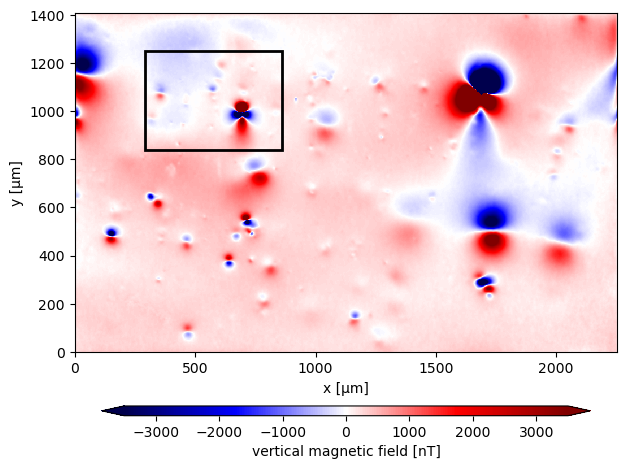

In [11]:
fig, axes = plt.subplots(1, 1, figsize=(7, 7))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
scale = 3500
data_up.bz.plot.pcolormesh(vmin=-scale, vmax=scale, cmap='seismic',  cbar_kwargs=cbar_kwargs)
axes.set_aspect("equal")


# define window for the selected anomaly
# window = [1500, 1850, 800, 1300] # single anomaly
# window = [1200, 1775, 950, 1200]
window = [290, 860, 840, 1250]
# window = [1200, 1800, 800, 1300]

rect = matplotlib.patches.Rectangle(
    xy=[window[0], window[2]],
    width=window[1] - window[0],
    height=window[3] - window[2],
    edgecolor="k",
    fill=False,
    linewidth=2,
)
axes.add_patch(rect)

# axes.text(window[0]-120, window[2]-60, 'selected source')

## Select anomaly

In [12]:
data = data.sel(x=slice(*window[:2]), y=slice(*window[2:]))
data_up = data_up.sel(x=slice(*window[:2]), y=slice(*window[2:]))

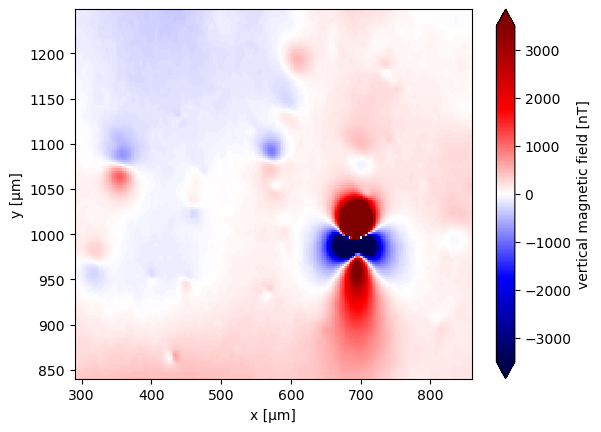

In [13]:
data_up.bz.plot.pcolormesh(cmap="seismic", vmax=scale, vmin=-scale)

In [14]:
stretched = skimage.exposure.rescale_intensity(
    data_up.tga, 
    in_range=tuple(np.percentile(data_up.tga, (1, 99))),
)
data_up = data_up.assign(tga_stretched=xr.DataArray(stretched, coords=data_up.coords))

In [15]:
# windows = mg.detect_anomalies(
#     data_up.tga_stretched, 
#     size_range=[25, 100],
#     size_increment=1.0,
#     threshold=0.01,
#     overlap=0.0,
#     exclude_border=2,
#     nsizes=50,
# )

windows = mg.detect_anomalies(
    data_up.tga_stretched, 
    size_range=[15, 45],
    size_increment=1.0,
    threshold=0.01,
    overlap=0.0,
    exclude_border=2,
    nsizes=50,
)

# windows = np.array([window])

# windows = mg.detect_anomalies(
#     data_up.tga_stretched, 
#     size_range=[30, 200],
#     size_increment=1.2,
#     threshold=0.025,
#     overlap=0.0,
#     exclude_border=30,
#     nsizes=20,
# )


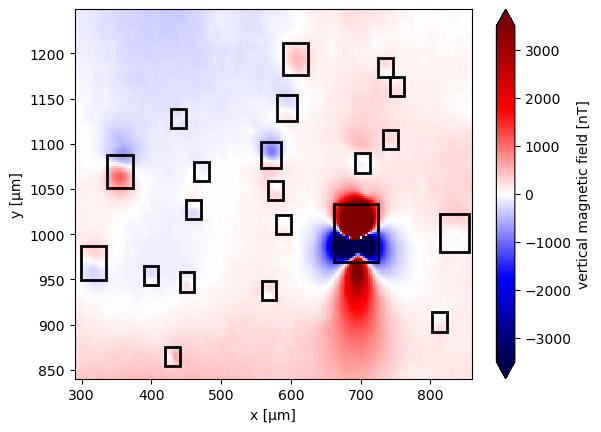

In [16]:
ax = plt.subplot(111)
data_up.bz.plot.pcolormesh(ax=ax, cmap="seismic", vmax=scale, vmin=-scale)
for window in windows:
    rect = matplotlib.patches.Rectangle(
        xy=[window[0], window[2]],
        width=window[1] - window[0],
        height=window[3] - window[2],
        edgecolor="k",
        fill=False,
        linewidth=2,
    )
    ax.add_patch(rect) 

## Non-linear dipole fitting

In [17]:
def goal_function_dipole(parameter, obs_data, coordinates, amplitude, x_0, y_0, z_0):
    bz = mg.dipole_bz(coordinates, 
                      ([parameter[0]*x_0], [parameter[1]*y_0], [parameter[2]*z_0]),
                     np.array([parameter[3], parameter[4], parameter[5]])*amplitude
                     )
    
    Res = np.linalg.norm(obs_data-bz.ravel())
    return(Res)

whole_table = vd.grid_to_table(data_up)
coordinates_whole = (whole_table.x, whole_table.y, whole_table.z)

In [18]:
data_copy = data.copy(deep=True)
data_up_copy = data_up.copy(deep=True)
data_up = data_up.assign(dipole_nonlinear=(['y','x'], np.zeros_like(data_up.bz)))


estimated_dipole_moments_dip = []
positions_dipole = []
base_levels_dipole = []

for window in rich.progress.track(np.array(windows), total = len(np.array(windows))):

    anomaly = data_up_copy.sel(x=slice(*window[:2]), y=slice(*window[2:]))

    table = vd.grid_to_table(anomaly)
    coordinates = (anomaly.x, anomaly.y, anomaly.z)
    
    position, base_level = mg.euler_deconvolution(
            anomaly.bz, 
            anomaly.x_deriv, 
            anomaly.y_deriv, 
            anomaly.z_deriv,
        )
    
    data_minus_background = anomaly.bz.values - base_level
    anomaly = anomaly.assign(data_minus_background=(['y','x'], data_minus_background))
    anomaly.data_minus_background.attrs = {"long_name": "dipole-model", "units": "nT"}

    moment, covariance, r2, SNR = mg.dipole_moment_inversion(
        anomaly.data_minus_background, position,
    )
    
    anomaly_table=vd.grid_to_table(anomaly)
    amplitude = np.linalg.norm(moment)
    
    
    ## SCIPY MINIMIZATION DIPOLE
    args_dip=(anomaly_table.bz.ravel(), 
         ( anomaly_table.x.values,
           anomaly_table.y.values, 
           anomaly_table.z.values.ravel()),
           amplitude, position[0], position[1], position[2])
    
    minimization=sp.optimize.minimize(goal_function_dipole, (1, 1, 1,
                                                      moment[0]/amplitude,
                                                      moment[1]/amplitude,
                                                      moment[2]/amplitude),
                                      args=args_dip,
                                      method='Nelder-Mead', options=dict(maxiter=1000))
    
    if minimization.success:
        
        moment = np.array([minimization['x'][3], minimization['x'][4], minimization['x'][5]])*amplitude
        position = np.array([minimization['x'][0]*position[0], 
                             minimization['x'][1]*position[1],
                             minimization['x'][2]*position[2]])
    estimated_dipole_moments_dip.append(moment)
    positions_dipole.append(position)
    base_levels_dipole.append(base_level)

    pred = mg.dipole_bz(coordinates_whole, 
              position,
              moment
             )
    # data_up = data_up.assign(dipole_nonlinear=(['y','x'], data_up.dipole_nonlinear.values + np.reshape(pred, np.shape(data_up.bz))))

    shape = np.shape(data_up.bz)
    data_up.dipole_nonlinear.values += pred.reshape(shape)
    
    discard = mg.dipole_bz(coordinates_whole, position, moment)
    data_copy.bz.values -= discard.reshape(shape)
    data_up_copy = (
                hm.upward_continuation(data_copy.bz, height_difference)
                .assign_attrs(data_copy.bz.attrs)
                .to_dataset(name="bz")
                .assign_coords(x=data_copy.x, y=data_copy.y)
                .assign_coords(z=data_copy.z + height_difference)
                   )
    data_up_copy = data_up_copy.assign(mg.data_gradients(data_up_copy.bz))



Output()

In [12]:
# data_anomaly = data_anomaly.assign(dipole_nonlinear=(['y','x'], pred))
data_up = data_up.assign(residual_dipole=(['y','x'], data_up.bz.values - data_up.dipole_nonlinear.values))

data_up.dipole_nonlinear.attrs = {"long_name": "dipole-model", "units": "nT"}
data_up.residual_dipole.attrs = {"long_name": "residual-dipole-model", "units": "nT"}


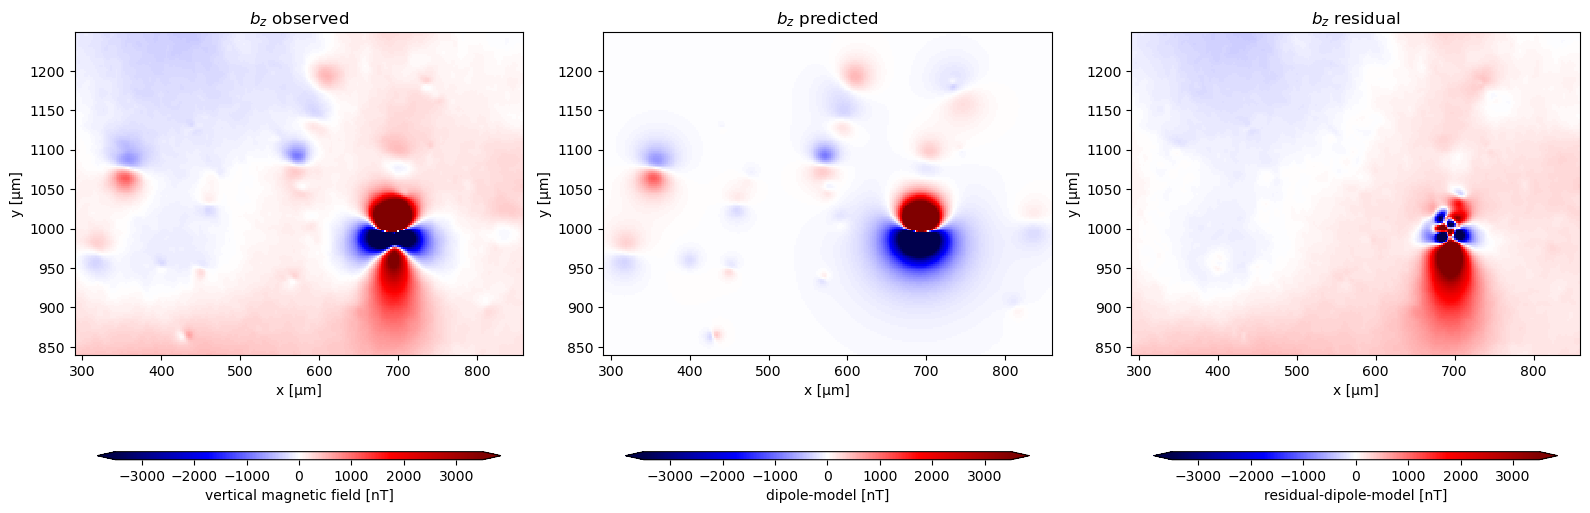

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 10))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
vmax =  3500
vmin = -3500 #data['bz_total'].values.min()
for field, ax in zip(["bz", "dipole_nonlinear", "residual_dipole"], axes.ravel()):

    data_up[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
for ax, title in zip(axes.ravel(), [r'$b_z$ observed', r'$b_z$ predicted', r'$b_z$ residual']):
    ax.set_aspect("equal")
    ax.set_title(title)

plt.tight_layout()

## Spherical Harmonic fitting

In [14]:
data_copy = data.copy(deep=True)
data_up_copy = data_up.copy(deep=True)
data_up = data_up.assign(spherical_harmonic=(['y','x'], np.zeros_like(data_up.bz)))

estimated_dipole_moments_SH = []
positions_SH = []
base_levels_SH = []

for window in rich.progress.track(np.array(windows), total = len(np.array(windows))):

    anomaly = data_up_copy.sel(x=slice(*window[:2]), y=slice(*window[2:]))
    
    position, base_level = mg.euler_deconvolution(
            anomaly.bz, 
            anomaly.x_deriv, 
            anomaly.y_deriv, 
            anomaly.z_deriv,
        )
    
    data_minus_background = anomaly.bz.values - base_level
    anomaly = anomaly.assign(data_minus_background=(['y','x'], data_minus_background))
    anomaly.data_minus_background.attrs = {"long_name": "dipole-model", "units": "nT"}

    anomaly_table=vd.grid_to_table(anomaly)
    coordinates = (anomaly_table.x, anomaly_table.y, anomaly_table.z)

###################################################################
    # moment, covariance, r2, SNR = mg.dipole_moment_inversion(
    #     anomaly.data_minus_background, position,
    # )
    
    # anomaly_table=vd.grid_to_table(anomaly)
    # amplitude = np.linalg.norm(moment)
    
    
    # ## SCIPY MINIMIZATION DIPOLE
    # args_dip=(anomaly_table.bz.ravel(), 
    #      ( anomaly_table.x.values,
    #        anomaly_table.y.values, 
    #        anomaly_table.z.values.ravel()),
    #        amplitude, position[0], position[1], position[2])
    
    # minimization=sp.optimize.minimize(goal_function_dipole, (1, 1, 1,
    #                                                   moment[0]/amplitude,
    #                                                   moment[1]/amplitude,
    #                                                   moment[2]/amplitude),
    #                                   args=args_dip,
    #                                   method='Nelder-Mead', options=dict(maxiter=1000))
    
    # if minimization.success:
        
    #     moment = np.array([minimization['x'][3], minimization['x'][4], minimization['x'][5]])*amplitude
    #     position = np.array([minimization['x'][0]*position[0], 
    #                          minimization['x'][1]*position[1],
    #                          minimization['x'][2]*position[2]])
###################################################################    
    sph = mt.SphericalHarmonicsBz(position, damping=1e-1, min_degree=1, max_degree=5).fit(coordinates, anomaly_table.data_minus_background)
    sph.update_location(coordinates, anomaly_table.data_minus_background)
    
    ####
    estimated_dipole_moments_SH.append(sph.magnetic_moment_)
    positions_SH.append(sph.location)
    base_levels_SH.append(base_level)

    pred_sph = sph.predict(coordinates_whole).reshape(data_up.bz.shape)

    shape = np.shape(data_up.bz)
    data_up.spherical_harmonic.values += pred_sph.reshape(shape)
    
    data_copy.bz.values -= pred_sph.reshape(shape)
    data_up_copy = (
                hm.upward_continuation(data_copy.bz, height_difference)
                .assign_attrs(data_copy.bz.attrs)
                .to_dataset(name="bz")
                .assign_coords(x=data_copy.x, y=data_copy.y)
                .assign_coords(z=data_copy.z + height_difference)
                   )
    data_up_copy = data_up_copy.assign(mg.data_gradients(data_up_copy.bz))



Output()

In [15]:
data_up = data_up.assign(residual_spherical=(['y','x'], data_up.bz.values - data_up.spherical_harmonic.values))

data_up.spherical_harmonic.attrs = {"long_name": "spherical-model", "units": "nT"}
data_up.residual_spherical.attrs = {"long_name": "residual-spherical", "units": "nT"}


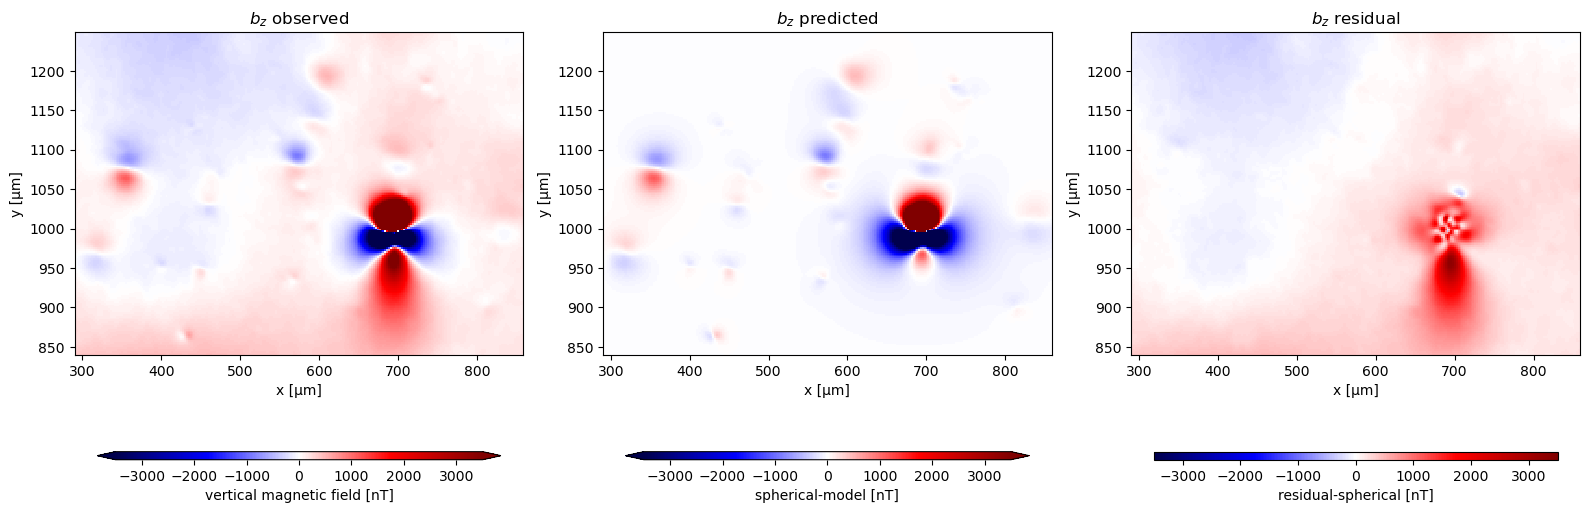

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 10))
cbar_kwargs = dict(orientation="horizontal", aspect=50, pad=0.1, shrink=0.9)
vmax =  3500
vmin = -3500 #data['bz_total'].values.min()
for field, ax in zip(["bz", "spherical_harmonic", "residual_spherical"], axes.ravel()):

    data_up[field].plot.pcolormesh(ax=ax, cmap="seismic", cbar_kwargs=cbar_kwargs, vmax=vmax, vmin=vmin)
for ax, title in zip(axes.ravel(), [r'$b_z$ observed', r'$b_z$ predicted', r'$b_z$ residual']):
    ax.set_aspect("equal")
    ax.set_title(title)

plt.tight_layout()

## Figure

In [17]:
zooms = [
# [325, 380, 1050, 1110], 
[330, 380, 1045, 1110], 
# [380, 415,  935,  970],
[390, 410,  935,  970],
# [670, 730, 1060, 1120]   
[680, 720, 1060, 1120]   
]

In [18]:
zooms = [
[330, 380, 1045, 1110], 
[680, 720, 1060, 1120],
[390, 410,  935,  970]
]

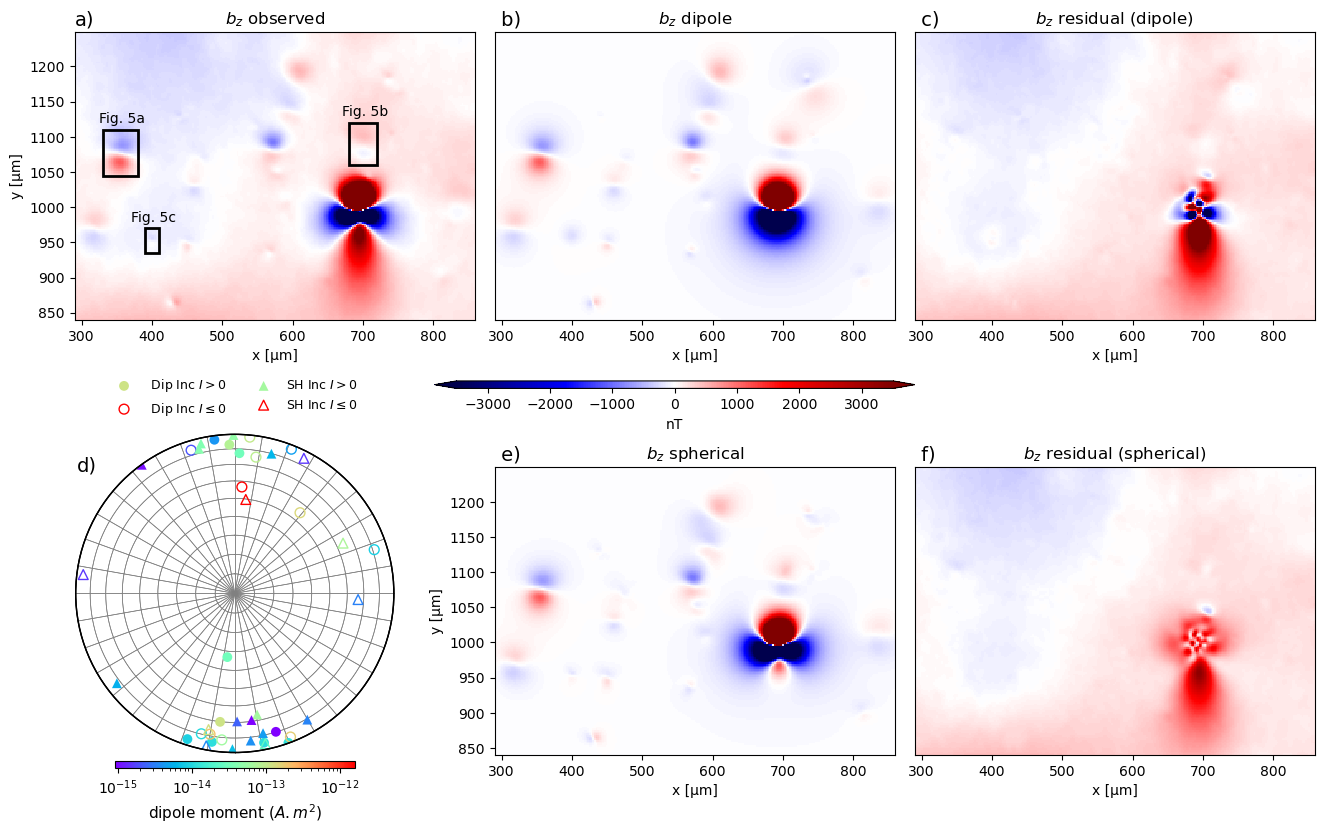

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))#, sharey='row', sharex='col')

vmax = 3500
vmin = -3500

# ===== FIRST ROW =====
# Observed data (reference for colorbar)
im = data_up["bz"].plot.pcolormesh(
    ax=axes[0, 0],
    cmap="seismic",
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

letters = ["a", "b", "c"]
for letter, window in zip(letters, zooms):
    rect = matplotlib.patches.Rectangle(
        xy=[window[0], window[2]],
        width=window[1] - window[0],
        height=window[3] - window[2],
        edgecolor="k",
        fill=False,
        linewidth=2,
    )
    axes[0,0].add_patch(rect)  

    axes[0,0].text((window[0]+window[1])/2-30, window[3]+10, f'Fig. 5{letter}')

# Dipole prediction
data_up["dipole_nonlinear"].plot.pcolormesh(
    ax=axes[0, 1],
    cmap="seismic",
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

# Dipole residual
data_up["residual_dipole"].plot.pcolormesh(
    ax=axes[0, 2],
    cmap="seismic",
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

# ===== SECOND ROW =====
# Empty axis (reserved for stereonet later)
axes[1, 0].axis("off")

# Spherical harmonic prediction
data_up["spherical_harmonic"].plot.pcolormesh(
    ax=axes[1, 1],
    cmap="seismic",
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

# Spherical residual
data_up["residual_spherical"].plot.pcolormesh(
    ax=axes[1, 2],
    cmap="seismic",
    vmin=vmin,
    vmax=vmax,
    add_colorbar=False
)

# ===== TITLES AND ASPECT =====
titles = [
    r"$b_z$ observed", r"$b_z$ dipole", r"$b_z$ residual (dipole)",
    "", r"$b_z$ spherical", r"$b_z$ residual (spherical)"
]

for ax, title in zip(axes.ravel(), titles):
    ax.set_title(title)
    ax.set_aspect("equal")


# ===== REMOVE Y-AXIS LABELS AND TICKS FROM SELECTED AXES =====
for ax in [axes[0, 1], axes[0, 2], axes[1, 2]]:
    ax.set_ylabel("")                 # remove y-axis label
    ax.set_yticklabels([])            # remove tick labels
    ax.tick_params(axis='y', which='both', length=0)  # remove tick marks


# ===== CREATE COLORBAR AXIS MANUALLY =====
# [left, bottom, width, height] in figure coordinates
cbar_ax = fig.add_axes([0.35, 0.5, 0.3, 0.0075])#[0.11, 0.15, 0.23, 0.015])

cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    extend='both',
    orientation="horizontal"
)

cbar.set_label("nT")


## Add stereogram
ax = fig.add_axes([0.05, 0.12, 0.35, 0.35])

projection_SH = mg.StereographicProjection(estimated_dipole_moments_SH)
projection_dip = mg.StereographicProjection(estimated_dipole_moments_dip)

cmap = "rainbow"
cmap_norm = matplotlib.colors.LogNorm #Normalize
kwargs = dict(
    s=50, cmap=cmap, cmap_norm=cmap_norm
)   

# Plota a projeção estereográfica
tmp = projection_dip.plot(ax=ax, draw_cross=False, add_radial_grid=True, label=" Dip Inc", 
                          add_legend=False, add_ticks=False, **kwargs)

tmp = projection_SH.plot(ax=ax, draw_cross=False, add_radial_grid=True, marker='^', label="SH Inc", 
                         add_legend=False, add_ticks=False, **kwargs)
clb = fig.colorbar(
        tmp, 
        # cax=fig.add_axes([0.12, -0.025, 0.73, 0.0075]), 
        cax=fig.add_axes([0.15, 0.12, 0.15,  0.0075]), 
        # format="%.0g",
        label="A.m²",
        orientation="horizontal"
    )
    
clb.set_label(label="dipole moment ($A.m^2$)", fontsize=11)
clb.ax.tick_params(labelsize=10)

ax.text(0.05, 0.85, f"d)", transform=ax.transAxes, fontsize=14, zorder=5)

ax.legend(ncol=2, fontsize=9, loc='upper center',bbox_to_anchor=(0.5, 1.15), frameon=False)


for ax, letter in zip(axes.ravel(), r"a)| b)| c)| | e)| f)".split('|')):
    ax.text(0, 1.025, f"{letter}", transform=ax.transAxes, fontsize=14, zorder=5)



plt.subplots_adjust(hspace=0.3, wspace=0.05)

# plt.savefig(figure_dir / "real_data_results.png",
#             dpi=300, bbox_inches="tight", transparent=True)

plt.show()

## Zooms

In [20]:
# fig, axes = plt.subplots(3, 3, figsize=(10, 10), sharey='row')#, sharex='col')

# for i, window in enumerate(zooms):
    
#     # find the anomaly within the zoom window
#     x_dip = np.array(positions_dipole)[:,0]
#     y_dip = np.array(positions_dipole)[:,1]
#     z_dip = np.array(positions_dipole)[:,2]    
    
#     x_SH = np.array(positions_SH)[:,0]
#     y_SH = np.array(positions_SH)[:,1]
#     z_SH = np.array(positions_SH)[:,2]

#     xmin, xmax, ymin, ymax = window
#     mask = (x_dip >= xmin) & (x_dip <= xmax) & (y_dip >= ymin) & (y_dip <= ymax)

#     # get position and moment
#     pos_dip = np.array(positions_dipole)[mask]
#     pos_SH = np.array(positions_SH)[mask]

#     m_dip = np.array(estimated_dipole_moments_dip)[mask]
#     m_SH = np.array(estimated_dipole_moments_SH)[mask]

#     # get base level
#     base_level = (np.array(base_levels_SH)[mask])
#     window_plot = data_up.sel(x=slice(*window[:2]), y=slice(*window[2:]))
    
#     bz_corrected = window_plot["bz"] - base_level
#     scale = vd.maxabs(bz_corrected)
    
#     # Plot bz - base_level
#     im = bz_corrected.plot.pcolormesh(
#         ax=axes[i,0],
#         cmap="seismic",
#         vmin=-scale,
#         vmax=scale,
#         add_colorbar=False
#     )

#     window_plot["dipole_nonlinear"].plot.pcolormesh(
#     ax=axes[i,1],
#     cmap="seismic",
#     vmin=-scale,
#     vmax=scale,
#     add_colorbar=False)

#     # print the dip position info
#     if len(pos_dip) > 0:
#             xd, yd, zd = pos_dip[0]
#             texto_dip = f"({xd:.1f}, {yd:.1f}, {zd:.1f})"
#             axes[i,1].text(0.95, 0.05, texto_dip, 
#                           transform=axes[i,1].transAxes,
#                           fontsize=8, color='black',
#                           ha='right', va='bottom', 
#                           bbox=dict(facecolor='white', alpha=0.9, edgecolor='none', boxstyle='round,pad=0.3'))
        
#     rmse_dip = np.mean(bz_corrected.values-window_plot.dipole_nonlinear.values)**2
#     rmse_SH= np.mean(bz_corrected.values-window_plot.spherical_harmonic.values)**2

#     window_plot["spherical_harmonic"].plot.pcolormesh(
#     ax=axes[i,2],
#     cmap="seismic",
#     vmin=-scale,
#     vmax=scale,
#     add_colorbar=False)

#     # print the SH position info
#     if len(pos_SH) > 0:
#             xs, ys, zs = pos_SH[0]
#             texto_sh = f"({xs:.1f}, {ys:.1f}, {zs:.1f})"
#             axes[i,2].text(0.95, 0.05, texto_sh, 
#                           transform=axes[i,2].transAxes, 
#                           fontsize=8, color='black',
#                           ha='right', va='bottom',
#                           bbox=dict(facecolor='white', alpha=0.9, edgecolor='none', boxstyle='round,pad=0.3'))

# # for ax in axes.ravel():
# #     ax.set_aspect("equal")

# axes[0,0].set_title('Observed Bz - basel level')
# axes[0,1].set_title('Nonlinear Dipole Model Bz')
# axes[0,2].set_title('Spherical Harmonic Model Bz')

17.802141396115417
23.425088317854875

44.220198670582434
77.34096577344596

81.65810782385044
9.567067063045286



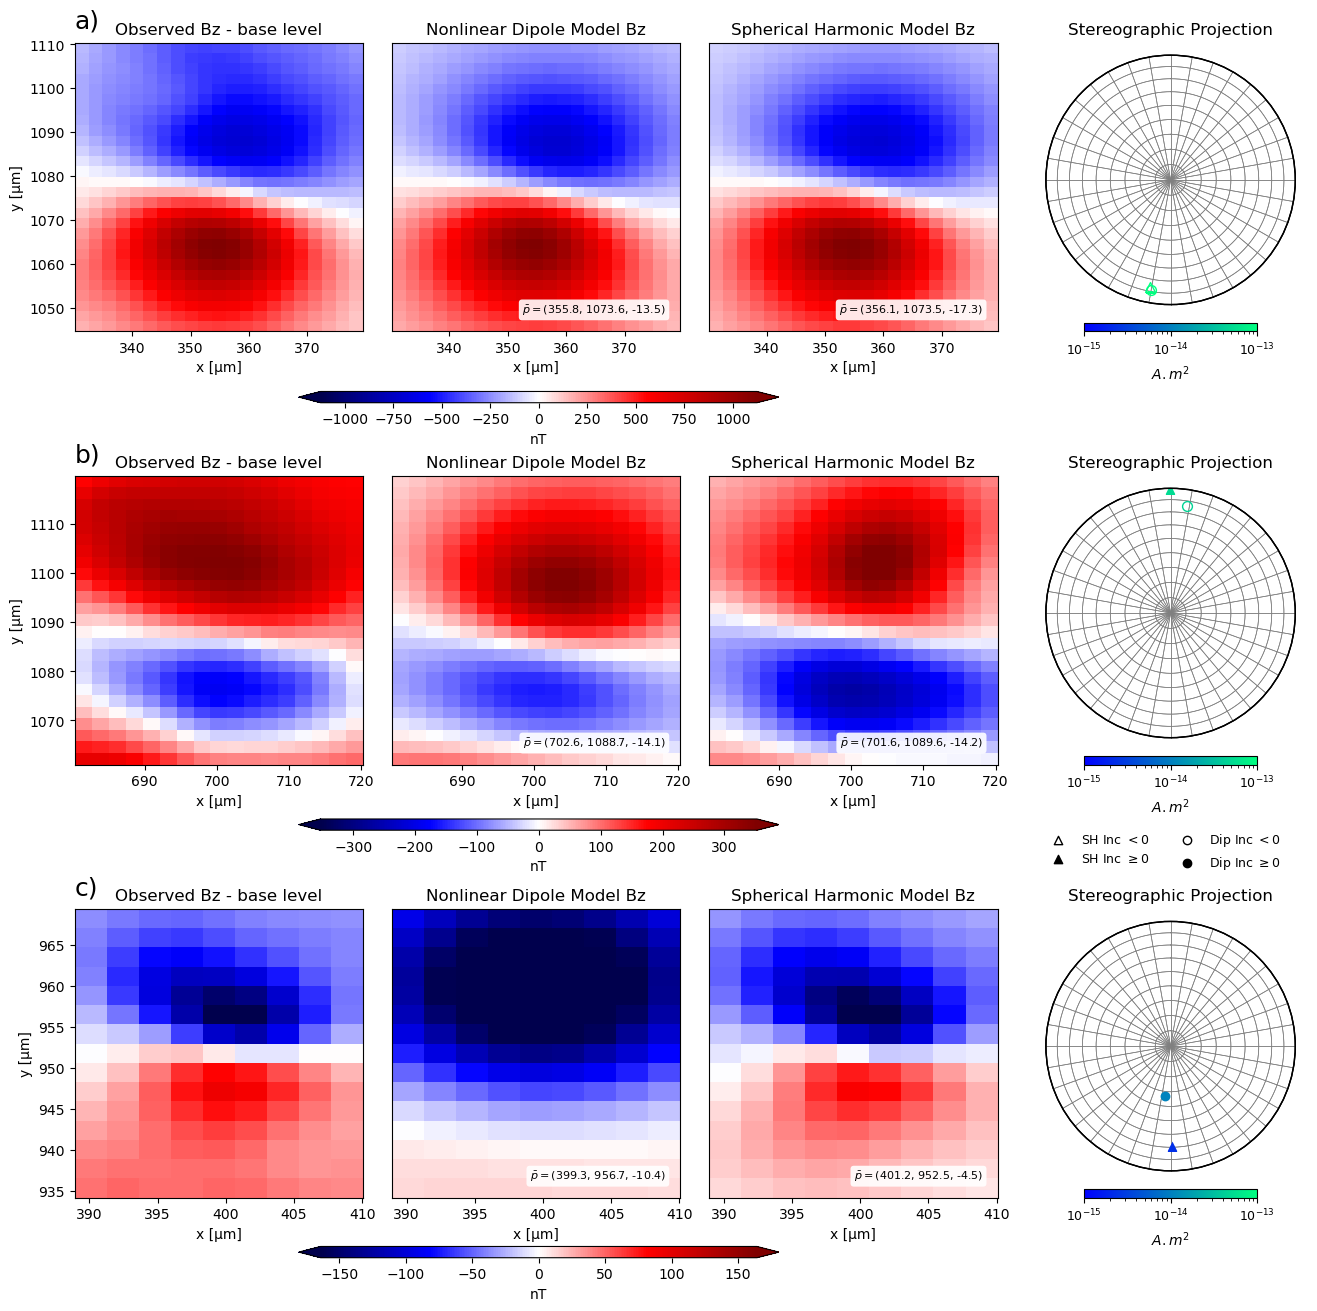

In [21]:
fig, axes = plt.subplots(len(zooms), 4, figsize=(16, 5 * len(zooms))) 

cmap = "rainbow"
cmap_norm = mcolors.LogNorm # Normalize
kwargs = dict(s=50, cmap=cmap, cmap_norm=cmap_norm)

ims = []
for i, window in enumerate(zooms):
    
     # find the anomaly within the zoom window
    x_dip = np.array(positions_dipole)[:,0]
    y_dip = np.array(positions_dipole)[:,1]
    z_dip = np.array(positions_dipole)[:,2]    
    
    x_SH = np.array(positions_SH)[:,0]
    y_SH = np.array(positions_SH)[:,1]
    z_SH = np.array(positions_SH)[:,2]

    xmin, xmax, ymin, ymax = window
    mask = (x_dip >= xmin) & (x_dip <= xmax) & (y_dip >= ymin) & (y_dip <= ymax)

    # get position and moment
    pos_dip = np.array(positions_dipole)[mask]
    pos_SH = np.array(positions_SH)[mask]

    m_dip = np.array(estimated_dipole_moments_dip)[mask]
    m_SH = np.array(estimated_dipole_moments_SH)[mask]

    # get base level
    base_level = (np.array(base_levels_SH)[mask])
    window_plot = data_up.sel(x=slice(*window[:2]), y=slice(*window[2:]))
    
    bz_corrected = window_plot["bz"] - base_level
    scale = vd.maxabs(bz_corrected)
    
    # Plot bz - base_level
    im = bz_corrected.plot.pcolormesh(
        ax=axes[i,0],
        cmap="seismic",
        vmin=-scale,
        vmax=scale,
        add_colorbar=False
    )

    ims.append(im)
    
    window_plot["dipole_nonlinear"].plot.pcolormesh(
    ax=axes[i,1],
    cmap="seismic",
    vmin=-scale,
    vmax=scale,
    add_colorbar=False)

    # print the dip position info
    if len(pos_dip) > 0:
            xd, yd, zd = pos_dip[0]
            texto_dip = r"$\bar{p}=$"+f"({xd:.1f}, {yd:.1f}, {zd:.1f})"
            axes[i,1].text(0.95, 0.05, texto_dip, 
                          transform=axes[i,1].transAxes,
                          fontsize=8, color='black',
                          ha='right', va='bottom', 
                          bbox=dict(facecolor='white', alpha=0.9, edgecolor='none', boxstyle='round,pad=0.3'))
        
    rmse_dip = np.sqrt(np.mean(bz_corrected.values-window_plot.dipole_nonlinear.values)**2)

    window_plot["spherical_harmonic"].plot.pcolormesh(
    ax=axes[i,2],
    cmap="seismic",
    vmin=-scale,
    vmax=scale,
    add_colorbar=False)

    rmse_SH= np.sqrt(np.mean(bz_corrected.values-window_plot.spherical_harmonic.values)**2)
    
    print(rmse_dip)
    print(rmse_SH)
    print()
    
    # print the SH position info
    if len(pos_SH) > 0:
            xs, ys, zs = pos_SH[0]
            texto_sh = r"$\bar{p}=$"+f"({xs:.1f}, {ys:.1f}, {zs:.1f})"
            axes[i,2].text(0.95, 0.05, texto_sh, 
                          transform=axes[i,2].transAxes, 
                          fontsize=8, color='black',
                          ha='right', va='bottom',
                          bbox=dict(facecolor='white', alpha=0.9, edgecolor='none', boxstyle='round,pad=0.3'))

    # ==========================================
    # Stereograms
    # ==========================================
    
    # if len(m_dip) > 0 and len(m_SH) > 0:
    
    # projection
    projection_dip = mg.StereographicProjection(m_dip)
    projection_SH = mg.StereographicProjection(m_SH)


    vmin = 1.0e-15#min(m_dip.min(), m_SH.min()) * 0.1
    vmax = 1.0e-13#(m_dip.max(), m_SH.max()) * 10

    kwargs = dict(s=50, cmap="winter", vmin=vmin, vmax=vmax, cmap_norm=cmap_norm)

    # dipole model
    tmp = projection_dip.plot(
        ax=axes[i, 3], draw_cross=False, add_radial_grid=True, 
        label=" Dip Inc", add_legend=False, add_ticks=False, **kwargs
    )
    
    # SH (Spherical Harmonic) model
    tmp = projection_SH.plot(
        ax=axes[i, 3], draw_cross=False, add_radial_grid=True, marker='^', 
        label="SH Inc", add_legend=False, add_ticks=False, **kwargs
    )
    
    # colorbar
    clb = fig.colorbar(tmp, ax=axes[i, 3], orientation="horizontal", 
                       fraction=0.03, pad=0.02)
    
    clb.set_label(label="$A.m^2$", fontsize=10)
    clb.ax.tick_params(labelsize=9)

# titles
for i in range(3):    
    axes[i,0].set_title('Observed Bz - base level')
    axes[i,1].set_title('Nonlinear Dipole Model Bz')
    axes[i,2].set_title('Spherical Harmonic Model Bz')
    axes[i,3].set_title('Stereographic Projection')

###
for i in range(3):
    for j in range(1,3):
        ax = axes[i,j]
        ax.set_ylabel("")                 # remove y-axis label
        ax.set_yticklabels([])            # remove tick labels
        ax.tick_params(axis='y', which='both', length=0)  # remove tick marks



##############################
cbar_ax = fig.add_axes([0.265, 0.64, 0.3, 0.0075])
cbar = fig.colorbar(
    ims[0],
    cax=cbar_ax,
    extend='both',
    orientation="horizontal"
)
cbar.set_label("nT")


cbar_ax = fig.add_axes([0.265, 0.355, 0.3, 0.0075])
cbar = fig.colorbar(
    ims[1],
    cax=cbar_ax,
    extend='both',
    orientation="horizontal"
)
cbar.set_label("nT")


cbar_ax = fig.add_axes([0.265, 0.07, 0.3, 0.0075])
cbar = fig.colorbar(
    ims[2],
    cax=cbar_ax,
    extend='both',
    orientation="horizontal"
)
cbar.set_label("nT")
##############################

# texts
axes[0,0].text(0, 1.05, 'a)', transform=axes[0,0].transAxes, fontsize=18)
axes[1,0].text(0, 1.05, 'b)', transform=axes[1,0].transAxes, fontsize=18)
axes[2,0].text(0, 1.05, 'c)', transform=axes[2,0].transAxes, fontsize=18)


#
axes[2,2].scatter([],[], color='k', marker='^', facecolor='w', label=r'SH Inc $< 0$')
axes[2,2].scatter([],[], color='k', marker='^', facecolor='k',  label=r'SH Inc $\geq 0$')
axes[2,2].scatter([],[], color='k', marker='o', facecolor='w', label=r'Dip Inc $<0$')
axes[2,2].scatter([],[], color='k', marker='o', facecolor='k',  label=r'Dip Inc $\geq 0$')

axes[2,2].legend(loc='center', bbox_to_anchor=(1.575, 1.2), ncol=2, frameon=False, fontsize=9)

plt.subplots_adjust(hspace=0.5, wspace=0.1)

# plt.savefig(figure_dir / "zoom_real_data_results.png",
#             dpi=300, bbox_inches="tight", transparent=True)

plt.show()